# 04. 학습 데이터: TabICL prior

v2 논문은 prior 생성 코드를 공개하지 않았습니다([`02_prior_primer`](02_prior_primer.ipynb)). 그래서 이 저장소는 같은 계열의 공개 prior인 TabICLv2의 graph prior(Qu et al., [soda-inria/tabicl](https://github.com/soda-inria/tabicl), BSD-3-Clause)로 학습 데이터를 만듭니다. 이 노트북은 그 prior가 논문의 prior와 무엇이 같고 다른지, 이 저장소가 무엇을 더했는지, 만든 데이터셋이 어떻게 생겼는지, 학습에 쓸 만큼 빨리 만들어지는지를 봅니다.

코드는 `src/minipfn/tabpfn_v2/prior.py`입니다.

다루는 흐름:

1. 논문 prior와 TabICL prior
2. 데이터셋 하나 보기
3. 한 batch의 크기
4. 여러 데이터셋 그려 보기
5. 데이터셋 200개의 통계
6. 회귀 출력의 구간 경계
7. 생성 속도
8. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from minipfn.tabpfn_v2 import prior as P

torch.set_num_threads(1)  # 생성 속도를 코어 하나 기준으로 잰다

## 1. 논문 prior와 TabICL prior

두 prior는 같은 생각에서 출발합니다. 무작위 DAG를 뽑고, 원인 노드에 무작위 점을 넣어 간선의 무작위 함수로 흘려 보낸 뒤, 일부 노드를 feature와 target으로 읽습니다. 세부는 다릅니다.

| | 논문 v2 prior (Methods) | TabICLv2 graph prior | 이 저장소 |
|---|---|---|---|
| 그래프 | growing network with redirection (scale-free) | 노드 쌍마다 Cauchy 분포로 정한 확률로 간선을 둔 DAG, 노드 2~32개 | TabICL |
| 간선 함수 | 작은 신경망(활성화 12종), 결정 나무, 이산화 | MLP, 결정 나무, 이산화, GP, 선형, 2차, EM 할당, 곱 | TabICL |
| 부모가 여럿일 때 | (논문에 없음) | 합, 곱, 최대, logsumexp, 이어 붙이기 중 하나 | TabICL |
| 원인 노드 입력 | 정규·균등·혼합, 원형 섞기 | 정규, 균등, 원, 가우시안 혼합, 공분산을 준 점 | TabICL |
| 범주형 feature | 이산화한 노드 | 이산화한 노드 (범주 최대 200개) | TabICL |
| Kumaraswamy 휘기 | 후처리 | 활성화 함수의 하나 | TabICL |
| 결측값 | MCAR | 없음 | **더함** (2절) |
| 데이터셋 크기 | 학습 행 ≤ 2,048 + 검증 128, feature 1~160, 셀 < 75,000 | 설정값 | **논문 규칙** (3절) |
| target | 분류: 클래스 10개 이하인 범주형 노드, 회귀: 연속값 노드 | 같음 | TabICL |

TabICL prior의 수치(노드 수, 함수 종류의 비율 등)는 TabICLv2 학습에 쓴 기본값을 그대로 씁니다. 논문 prior의 수치는 공개되지 않아서 비교할 수 없습니다.

## 2. 데이터셋 하나 보기

학습 행 8개, 검증 행 4개, feature 4개인 작은 분류 데이터셋을 하나 뽑아 실제 값을 봅니다. 결측값이 보이도록 이 예에서는 결측 확률을 1로 두었습니다. 학습 때는 데이터셋의 30%에만 결측값을 넣고, 결측 비율은 0~30% 사이에서 고르게 뽑습니다(논문에 수치가 없어서 여기서 정함).

In [3]:
small = P.TabPFNv2Prior("classification", seed=4, missing_dataset_prob=1.0, n_eval_rows=4)
batch = small.sample_batch(1, size=(8, 4))  # 학습 행 8개, feature 4개

table = pd.DataFrame(batch.x[0].numpy().round(2), columns=[f"x{i + 1}" for i in range(4)])
table["y"] = batch.y[0].numpy().astype(int).astype(object)
table.loc[batch.n_train :, "y"] = "?"  # 검증 행은 정답을 가린다
table.insert(0, "역할", ["학습"] * batch.n_train + ["검증 (정답을 가림)"] * 4)
display(table)

,역할,x1,x2,x3,x4,y
0,학습,0.68,0.96,2.14,0.43,0
1,학습,0.68,-0.96,2.14,0.43,0
2,학습,0.68,-0.96,-0.43,0.43,2
3,학습,0.68,-0.96,-0.43,0.43,4
4,학습,0.68,-0.96,-0.43,0.43,6
5,학습,-1.35,0.96,-0.43,-2.14,5
6,학습,-1.35,0.96,-0.43,0.43,1
7,학습,0.68,-0.96,-0.43,0.43,6
8,검증 (정답을 가림),-1.35,0.96,-0.43,0.43,?
9,검증 (정답을 가림),0.68,0.96,NaN,0.43,?


값은 TabICL이 열마다 표준화해서 내놓은 것이고, `NaN`이 이 저장소가 지운 칸입니다. 정답을 가린 행의 클래스는 모두 학습 행에도 나오게 합니다. 학습 행에 없는 클래스는 맞힐 방법이 없기 때문입니다. 클래스마다 한 행씩 먼저 학습 행에 넣고 나머지 학습 행을 무작위로 채웁니다(`_train_rows_cover_classes`). 그래서 클래스 수는 학습 행 수를 넘지 않게 뽑고, 분류 데이터셋의 학습 행은 2개 이상입니다. 처음에는 행 순서를 무작위로 섞어 조건이 맞을 때까지 다시 해 봤는데, 학습 행이 1개로 뽑히면 끝나지 않아 8×H100 실측 run이 멈췄습니다.

## 3. 한 batch의 크기

데이터셋 크기는 논문 Methods의 규칙을 따릅니다([`03` walkthrough](03_tabpfn_v2_paper_walkthrough.ipynb) 4절). 다만 GPU에서 데이터셋 여러 개를 한 tensor로 묶어 계산하려면 크기가 같아야 해서, 크기를 데이터셋마다가 아니라 batch마다 한 번 뽑습니다. 학습이 길어서 전체로 보면 같은 분포가 됩니다.

In [4]:
prior = P.TabPFNv2Prior("classification", seed=0)
rows = []
for _ in range(5):
    n_train, n_features = prior.sample_size()
    rows.append(
        {
            "학습 행": n_train,
            "검증 행": P.N_EVAL_ROWS,
            "feature": n_features,
            "셀 수": (n_train + P.N_EVAL_ROWS) * n_features,
        }
    )
display(pd.DataFrame(rows, index=[f"batch {i + 1}" for i in range(5)]))

,학습 행,검증 행,feature,셀 수
batch 1,1743,128,6,11226
batch 2,1305,128,31,44423
batch 3,1147,128,47,59925
batch 4,1916,128,30,61320
batch 5,826,128,3,2862


## 4. 여러 데이터셋 그려 보기

분류 데이터셋은 앞의 두 feature로, 회귀 데이터셋은 target과 가장 상관이 큰 feature 하나로 그립니다. 그림이 잘 보이도록 학습 행 300개, feature 4개로 크기를 고정하고 결측값은 넣지 않았습니다. 무작위로 뽑은 feature 두 개는 클래스와 거의 관계가 없는 경우가 많아서, [`02_prior_primer`](02_prior_primer.ipynb)처럼 앞의 두 feature가 연속값이고 그 둘로 클래스를 꽤 맞힐 수 있는 데이터셋(kNN 정확도가 가장 큰 클래스의 비율보다 0.2 이상 높음)만 골라 그립니다.

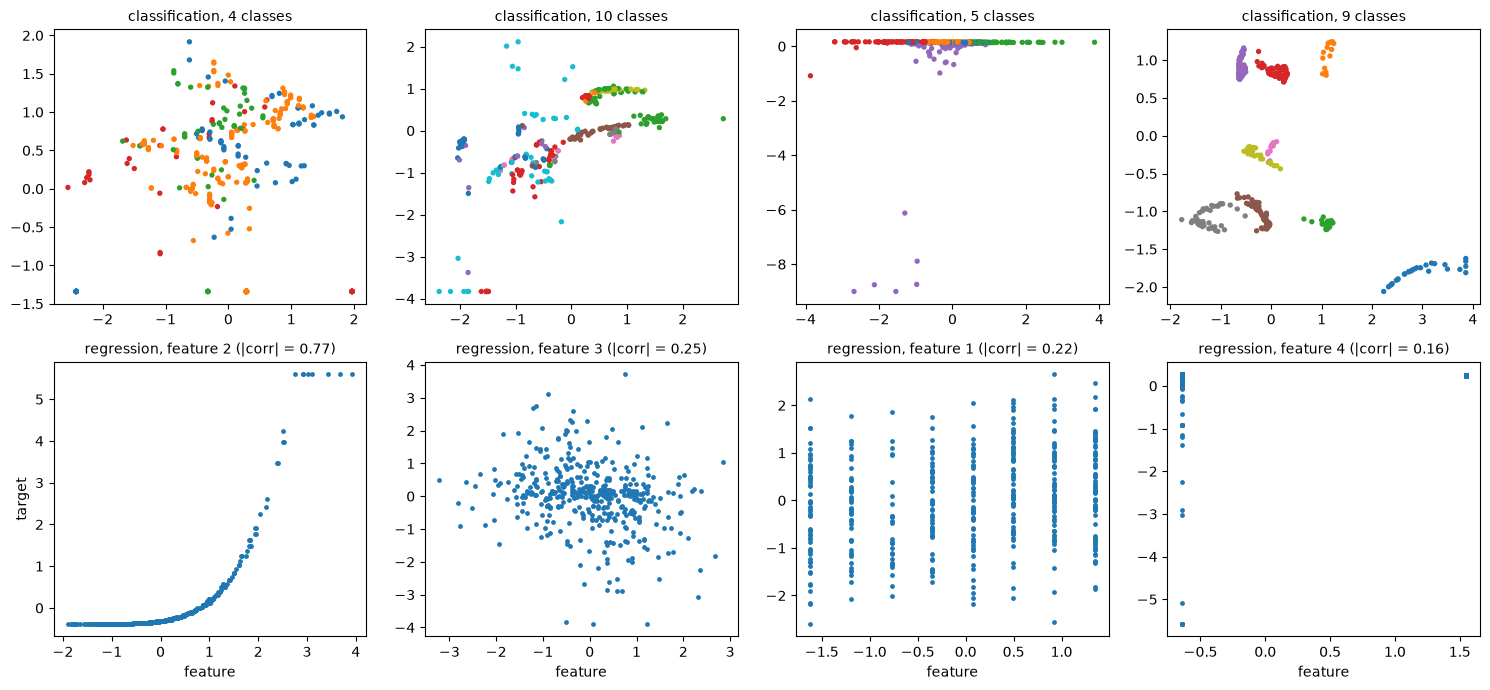

In [5]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier

clf_prior = P.TabPFNv2Prior("classification", seed=10, missing_dataset_prob=0.0)
reg_prior = P.TabPFNv2Prior("regression", seed=10, missing_dataset_prob=0.0)
# TabICL은 numpy·torch의 전역 난수를 쓰므로, 회귀 batch를 먼저 뽑고 분류 데이터셋을 고른다
reg = reg_prior.sample_batch(4, size=(300, 4))
cv = KFold(3, shuffle=True, random_state=0)
shown = []
while len(shown) < 4:
    one = clf_prior.sample_batch(1, size=(300, 4))  # 데이터셋 하나
    x, y = one.x[0], one.y[0]
    labels = y.long().numpy()
    if min(len(torch.unique(x[:, j])) for j in range(2)) <= 20:
        continue  # 점이 겹쳐 보이지 않도록 앞의 두 feature가 연속값인 것만
    acc = cross_val_score(KNeighborsClassifier(15), x[:, :2].numpy(), labels, cv=cv).mean()
    if acc - np.bincount(labels).max() / len(labels) > 0.2:
        shown.append((x, y))

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, (x, y) in zip(axes[0], shown, strict=True):
    ax.scatter(x[:, 0], x[:, 1], c=y, cmap="tab10", vmin=0, vmax=9, s=8)
    ax.set_title(f"classification, {len(torch.unique(y))} classes", fontsize=10)
for ax, x, y in zip(axes[1], reg.x, reg.y, strict=True):
    corr = [abs(np.corrcoef(x[:, j], y)[0, 1]) for j in range(x.shape[1])]
    j = int(np.nanargmax(corr))
    ax.scatter(x[:, j], y, s=6, color="C0")
    ax.set_title(f"regression, feature {j + 1} (|corr| = {corr[j]:.2f})", fontsize=10)
    ax.set_xlabel("feature")
axes[1, 0].set_ylabel("target")
plt.tight_layout()
plt.show()

[`02_prior_primer`](02_prior_primer.ipynb) 7절의 그림과 비슷하게 덩어리, 끊긴 관계, 몇 개의 값에 몰린 feature가 섞여 나옵니다. 몇 개의 값에 몰린 feature는 이산화한 노드에서 나온 범주형 feature입니다. 회귀 target도 매끄러운 곡선, 두 무리로 갈린 값, 거의 관계없는 점들이 섞여 있습니다.

TabICL prior는 같은 시드여도 파이썬을 새로 띄울 때마다(문자열 hash 시드 `PYTHONHASHSEED`가 다르면) 다른 데이터셋을 만듭니다. 그래서 이 절의 그림은 노트북을 실행할 때마다 바뀝니다. 학습에는 영향이 없습니다.

## 5. 데이터셋 200개의 통계

학습 때와 같은 설정(크기 규칙, 결측값 30%)으로 분류 데이터셋 200개를 뽑아 셉니다. 고유값이 10개 이하인 열을 "범주형처럼 보이는 열"로 셉니다.

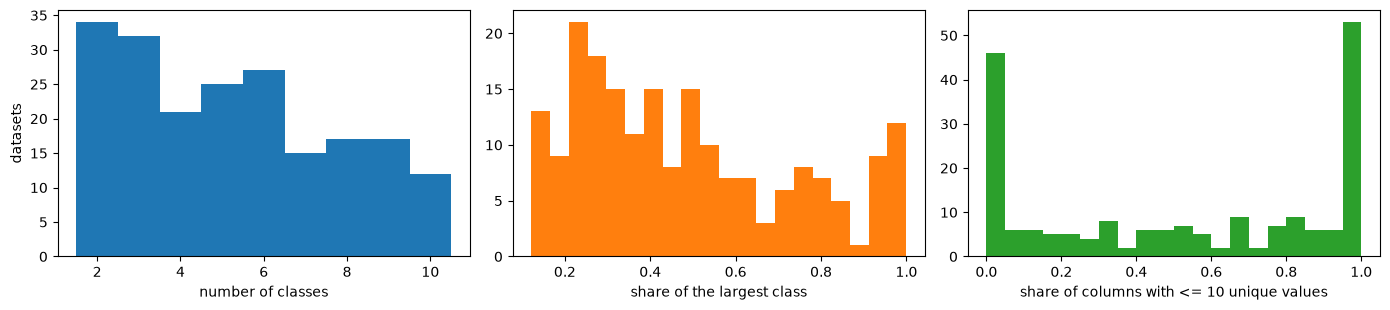

,값
평균 클래스 수,5.2
가장 큰 클래스가 70%를 넘는 데이터셋,24%
범주형처럼 보이는 열이 있는 데이터셋,78%
결측값이 있는 데이터셋,33%


In [6]:
stats_prior = P.TabPFNv2Prior("classification", seed=20)
records = []
for _ in range(50):
    batch = stats_prior.sample_batch(4)
    for x, y in zip(batch.x, batch.y, strict=True):
        counts = torch.bincount(y.long())
        n_unique = [len(torch.unique(col[~torch.isnan(col)])) for col in x.T]
        records.append(
            {
                "classes": int((counts > 0).sum()),
                "majority": float(counts.max() / counts.sum()),
                "categorical_like": float(np.mean([n <= 10 for n in n_unique])),
                "missing": float(torch.isnan(x).float().mean()),
            }
        )
stats = pd.DataFrame(records)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
axes[0].hist(stats["classes"], bins=np.arange(1.5, 11.5), color="C0")
axes[0].set_xlabel("number of classes")
axes[1].hist(stats["majority"], bins=20, color="C1")
axes[1].set_xlabel("share of the largest class")
axes[2].hist(stats["categorical_like"], bins=20, color="C2")
axes[2].set_xlabel("share of columns with <= 10 unique values")
axes[0].set_ylabel("datasets")
plt.tight_layout()
plt.show()

display(
    pd.DataFrame(
        {
            "값": [
                f"{stats['classes'].mean():.1f}",
                f"{(stats['majority'] > 0.7).mean():.0%}",
                f"{(stats['categorical_like'] > 0).mean():.0%}",
                f"{(stats['missing'] > 0).mean():.0%}",
            ]
        },
        index=[
            "평균 클래스 수",
            "가장 큰 클래스가 70%를 넘는 데이터셋",
            "범주형처럼 보이는 열이 있는 데이터셋",
            "결측값이 있는 데이터셋",
        ],
    )
)

클래스 수는 TabICL 기본값대로 2~10개에서 고르게 뽑습니다. v1 prior는 이진 분류가 65%였는데([`02_tabpfn/03`](../02_tabpfn/03_tabpfn_paper_walkthrough.ipynb) 3.4절), 여기서는 다중 클래스가 대부분입니다. 범주형처럼 보이는 열과 결측값도 자주 나와서, 실제 표에 흔한 이런 열을 학습 때 충분히 보게 됩니다.

## 6. 회귀 출력의 구간 경계

회귀 모델은 z-정규화한 target을 구간 5,000개의 bar distribution으로 예측합니다. 논문은 prior에서 데이터셋을 많이 뽑아 target을 모으고, 그 분포의 1/5,000 분위수들을 경계로 씁니다(Methods "Regression details", [`03` walkthrough](03_tabpfn_v2_paper_walkthrough.ipynb) 6절). `P.regression_borders`가 이 일을 합니다. 같은 값이 많은 데이터셋(이산화한 target 등)이 분위수를 끌어당기지 않도록 데이터셋마다 고유한 값만 모읍니다(여기서 정함). 여기서는 빨리 보려고 데이터셋 200개만 씁니다. 학습할 때는 더 많이 뽑습니다.

경계 5,001개, 12초
범위: -20.33 ~ 9.71


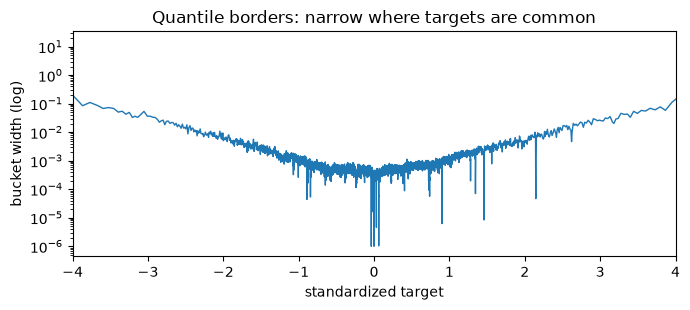

In [7]:
start = time.time()
borders = P.regression_borders(n_buckets=5000, n_datasets=200, seed=0)
print(f"경계 {len(borders):,}개, {time.time() - start:.0f}초")
print(f"범위: {borders[0]:.2f} ~ {borders[-1]:.2f}")

widths = borders[1:] - borders[:-1]
centers = (borders[1:] + borders[:-1]) / 2
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.semilogy(centers, widths, lw=1)
ax.set_xlim(-4, 4)
ax.set_xlabel("standardized target")
ax.set_ylabel("bucket width (log)")
ax.set_title("Quantile borders: narrow where targets are common")
plt.tight_layout()
plt.show()

target이 자주 나오는 0 근처는 구간이 좁고, 꼬리로 갈수록 넓어집니다. 0 근처에는 폭이 $10^{-6}$ 수준인 구간도 있습니다. 일부 데이터셋은 target 대부분이 한 값 근처에 몰리고 극단값 몇 개가 표준편차를 키워서, z-정규화한 값 대부분이 거의 0이 되기 때문입니다. 얼마나 흔한지 셉니다.

In [8]:
counter = P.TabPFNv2Prior("regression", seed=1, missing_dataset_prob=0.0)
near_zero, few_unique = [], []
for _ in range(100):
    n_train, n_features = counter.sample_size()
    _, y = counter._one_dataset(n_train, n_features)
    near_zero.append(float((y.abs() < 0.01).float().mean()))
    few_unique.append(len(torch.unique(y)) / len(y))
near_zero, few_unique = np.array(near_zero), np.array(few_unique)
print(f"target의 절반 이상이 |y| < 0.01인 데이터셋: {(near_zero > 0.5).mean():.0%}")
print(f"고유한 target 값이 행 수의 절반보다 적은 데이터셋: {(few_unique < 0.5).mean():.0%}")

target의 절반 이상이 |y| < 0.01인 데이터셋: 6%
고유한 target 값이 행 수의 절반보다 적은 데이터셋: 32%


회귀 데이터셋의 3분의 1 정도는 target이 이산적이고, 일부는 한 값에 몰려 있습니다. 분위수 경계는 이런 분포까지 그대로 반영하므로, 모델은 0 근처에서 아주 촘촘한 구간을 구분해야 합니다. 경계 정하는 방식은 논문을 따랐지만, 이런 몰림이 논문 prior에서도 이만큼 흔한지는 알 수 없습니다.

## 7. 생성 속도

학습 batch는 데이터셋 64개이고, 논문 규모는 200만 step입니다. GPU가 기다리지 않으려면 prior가 그만큼 빨리 데이터셋을 만들어야 합니다. 학습 설정(크기 규칙, 결측값)으로 데이터셋 40개씩을 만들며 코어 하나의 시간을 잽니다.

In [9]:
speed = {}
for task in ["classification", "regression"]:
    timer = P.TabPFNv2Prior(task, seed=30)
    times = []
    for _ in range(40):
        size = timer.sample_size()
        start = time.time()
        timer.sample_batch(1, size)
        times.append(time.time() - start)
    speed[task] = np.array(times)

display(
    pd.DataFrame(
        {
            task: {
                "평균 (초)": f"{t.mean():.3f}",
                "중앙값 (초)": f"{np.median(t):.3f}",
                "가장 오래 (초)": f"{t.max():.2f}",
                "코어 하나로 초당 데이터셋": f"{1 / t.mean():.1f}",
            }
            for task, t in speed.items()
        }
    )
)

,classification,regression
평균 (초),0.081,0.039
중앙값 (초),0.027,0.023
가장 오래 (초),0.65,0.25
코어 하나로 초당 데이터셋,12.3,25.8


대부분은 0.1초 안에 끝나고, 가끔 복잡한 그래프가 나오면 0.5초 가까이 걸립니다. 시간은 표의 크기보다 그래프의 복잡도에 더 좌우됩니다. 이 노트북을 만들 때 데이터셋 120개씩으로 잰 값은 코어 하나로 초당 17개 정도였습니다.

step 하나에 데이터셋 64개가 필요하므로, step 시간에 따라 필요한 코어 수는 다음과 같습니다. GPU 노드의 CPU 코어 수는 학습 단계에서 확인합니다.

In [10]:
per_core = 1 / np.mean(np.concatenate(list(speed.values())))
rows = []
for step_seconds in [1.0, 0.5, 0.25, 0.1]:
    needed = 64 / step_seconds
    rows.append(
        {
            "step 시간 (초)": step_seconds,
            "필요한 데이터셋 / 초": f"{needed:.0f}",
            "필요한 코어 수": int(np.ceil(needed / per_core)),
            "200만 step 시간": f"{2_000_000 * step_seconds / 3600:.0f}시간",
        }
    )
display(pd.DataFrame(rows))

,step 시간 (초),필요한 데이터셋 / 초,필요한 코어 수,200만 step 시간
0,1.00,64,4,556시간
1,0.50,128,8,278시간
2,0.25,256,16,139시간
3,0.10,640,39,56시간


step이 0.25초면 코어 십여 개로 prior가 GPU를 따라갑니다(측정할 때마다 조금씩 달라집니다). 학습은 GPU마다 데이터 생성 worker를 여러 개 띄워 batch를 미리 만들어 둡니다.

## 8. 정리

| | 이 저장소의 선택 | 코드 |
|---|---|---|
| prior 본체 | TabICLv2 graph prior (기본 설정) | `prior._graph_scm_classes`, `TabPFNv2Prior._one_dataset` |
| 데이터셋 크기 | 논문 규칙. batch마다 한 번 뽑는다 | `sample_table_size`, `TabPFNv2Prior.sample_size` |
| 결측값 | 데이터셋의 30%에 MCAR, 비율 0~30% (여기서 정함) | `TabPFNv2Prior._add_missing` |
| 분류 target | 클래스 2~10개(학습 행 수 이하), 검증 행의 클래스는 학습 행에도 있게 | `_train_rows_cover_classes` |
| 회귀 target | z-정규화한 값, 구간 5,000개, 경계는 prior target의 분위수 | `regression_borders` |
| 생성 속도 | 코어 하나로 초당 약 17개 | 7절 |

다음 단계에서는 이 prior로 [`model.py`](../../src/minipfn/tabpfn_v2/model.py)의 모델을 학습합니다.